<b>ML Experiment 5: Implementation of Dimensionality Reduction using PCA</b><br><br><b>Aim:</b> Verify PCA variance decomposition via SVD on standardized Wine features, plot a 2D loading biplot, and compare 5-fold CV KNN accuracy.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

In [2]:
wine = load_wine(as_frame=True)
features = wine.data
labels = wine.target

scaled_x = StandardScaler().fit_transform(features)

_, singular_vals, vt = np.linalg.svd(scaled_x, full_matrices=False)
svd_var_ratio = (singular_vals ** 2) / np.sum(singular_vals ** 2)

pca_90 = PCA(n_components=0.90)
x_reduced_90 = pca_90.fit_transform(scaled_x)

pca_all = PCA().fit(scaled_x)
table = pd.DataFrame({
    "PC": [f"PC{i}" for i in range(1, features.shape[1] + 1)],
    "Sklearn_Var_Ratio": np.round(pca_all.explained_variance_ratio_, 4),
    "SVD_Var_Ratio": np.round(svd_var_ratio, 4),
    "Cumulative_Ratio": np.round(np.cumsum(pca_all.explained_variance_ratio_), 4),
})

In [3]:
print("SVD vs PCA Variance Summary:")
print(table.head(9).to_string(index=False))
print(f"\nComponents retained for >= 90% variance: {pca_90.n_components_}")

pca_2 = PCA(n_components=2)
x_2d = pca_2.fit_transform(scaled_x)

knn_full = cross_val_score(KNeighborsClassifier(n_neighbors=5), scaled_x, labels, cv=5).mean()
knn_90 = cross_val_score(KNeighborsClassifier(n_neighbors=5), x_reduced_90, labels, cv=5).mean()
knn_2d = cross_val_score(KNeighborsClassifier(n_neighbors=5), x_2d, labels, cv=5).mean()

print(f"5-Fold CV KNN Accuracy (13 Features):           {knn_full:.4f}")
print(f"5-Fold CV KNN Accuracy ({pca_90.n_components_} PCs, 90% Var):     {knn_90:.4f}")
print(f"5-Fold CV KNN Accuracy (2 PCs):                 {knn_2d:.4f}")

SVD vs PCA Variance Summary:
 PC  Sklearn_Var_Ratio  SVD_Var_Ratio  Cumulative_Ratio
PC1             0.3620         0.3620            0.3620
PC2             0.1921         0.1921            0.5541
PC3             0.1112         0.1112            0.6653
PC4             0.0707         0.0707            0.7360
PC5             0.0656         0.0656            0.8016
PC6             0.0494         0.0494            0.8510
PC7             0.0424         0.0424            0.8934
PC8             0.0268         0.0268            0.9202
PC9             0.0222         0.0222            0.9424

Components retained for >= 90% variance: 8
5-Fold CV KNN Accuracy (13 Features):           0.9551
5-Fold CV KNN Accuracy (8 PCs, 90% Var):     0.9495
5-Fold CV KNN Accuracy (2 PCs):                 0.9663


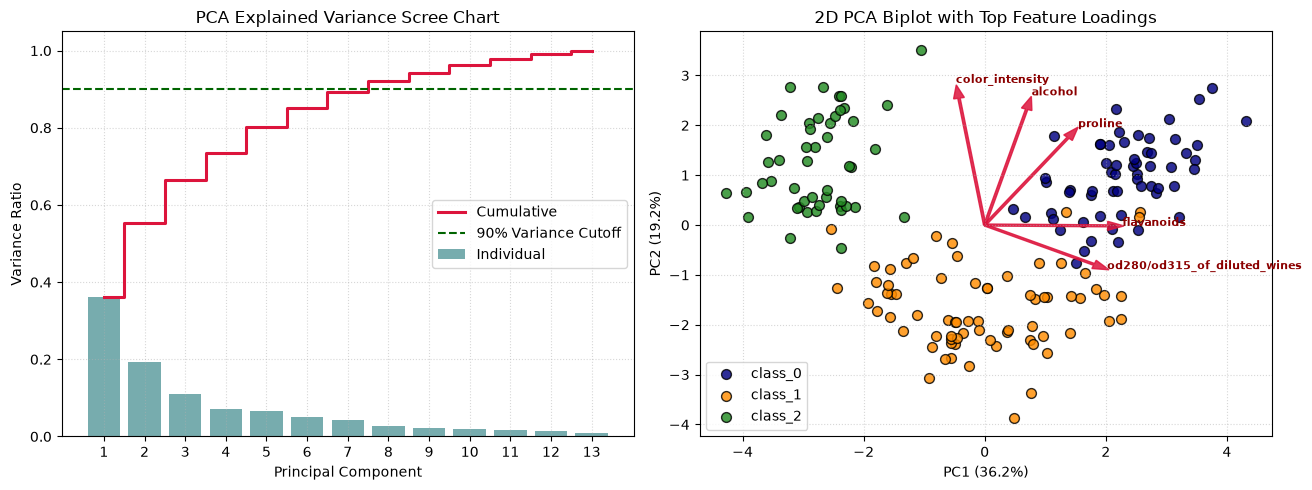

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13.5, 5))

comp_idx = np.arange(1, features.shape[1] + 1)
cum_ratio = np.cumsum(pca_all.explained_variance_ratio_)
ax[0].bar(comp_idx, pca_all.explained_variance_ratio_, color="cadetblue", alpha=0.85, label="Individual")
ax[0].step(comp_idx, cum_ratio, where="mid", color="crimson", linewidth=2.2, label="Cumulative")
ax[0].axhline(0.90, color="darkgreen", linestyle="--", label="90% Variance Cutoff")
ax[0].set_xticks(comp_idx)
ax[0].set_title("PCA Explained Variance Scree Chart")
ax[0].set_xlabel("Principal Component")
ax[0].set_ylabel("Variance Ratio")
ax[0].legend()
ax[0].grid(True, linestyle=":", alpha=0.5)

colors = ["navy", "darkorange", "forestgreen"]
for cls_idx, cls_label in enumerate(wine.target_names):
    sel = labels == cls_idx
    ax[1].scatter(x_2d[sel, 0], x_2d[sel, 1], color=colors[cls_idx], label=cls_label, alpha=0.82, edgecolor="black", s=50)

loadings = pca_2.components_.T
top_feats = np.argsort(np.linalg.norm(loadings, axis=1))[-5:]
for f_idx in top_feats:
    lx, ly = loadings[f_idx, 0] * 4.8, loadings[f_idx, 1] * 4.8
    ax[1].arrow(0, 0, lx, ly, color="crimson", width=0.04, head_width=0.18, alpha=0.85)
    ax[1].text(lx * 1.12, ly * 1.12, features.columns[f_idx], fontsize=8, color="darkred", fontweight="bold")

ax[1].set_title("2D PCA Biplot with Top Feature Loadings")
ax[1].set_xlabel(f"PC1 ({pca_2.explained_variance_ratio_[0] * 100:.1f}%)")
ax[1].set_ylabel(f"PC2 ({pca_2.explained_variance_ratio_[1] * 100:.1f}%)")
ax[1].legend()
ax[1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

<b>Observation:</b> PCA retains 90%+ cumulative variance in fewer components while preserving or slightly improving downstream KNN cross-validation accuracy.